optimal window for lin_acc: 3
optimal std for lin_acc: 10
optimal window for lin_acc_2: 1
optimal std for lin_acc_2: 1
optimal window for ang_vel_x: 1
optimal std for ang_vel_x: 1
i: 1, std: 1, score: 69.65991874161097
i: 1, std: 2, score: 60.933826917246314
i: 1, std: 3, score: 60.69186903257434
i: 1, std: 4, score: 60.60139128170202
i: 1, std: 5, score: 60.55853244126631
i: 1, std: 10, score: 60.50079115283093
i: 2, std: 1, score: 65.58956118812
i: 2, std: 2, score: 45.91728510354
i: 2, std: 3, score: 46.939571003766126
i: 2, std: 4, score: 47.14416528056548
i: 2, std: 5, score: 47.28331248323944
i: 2, std: 10, score: 53.86281364872942
i: 3, std: 1, score: 65.37885969717684
i: 3, std: 2, score: 41.04433142041291
i: 3, std: 3, score: 39.76794801786716
i: 3, std: 4, score: 41.2102784406923
i: 3, std: 5, score: 41.640812230802965
i: 3, std: 10, score: 42.22774902625224
i: 4, std: 1, score: 65.3664559234719
i: 4, std: 2, score: 40.14758031554044
i: 4, std: 3, score: 37.517609713115455
i:

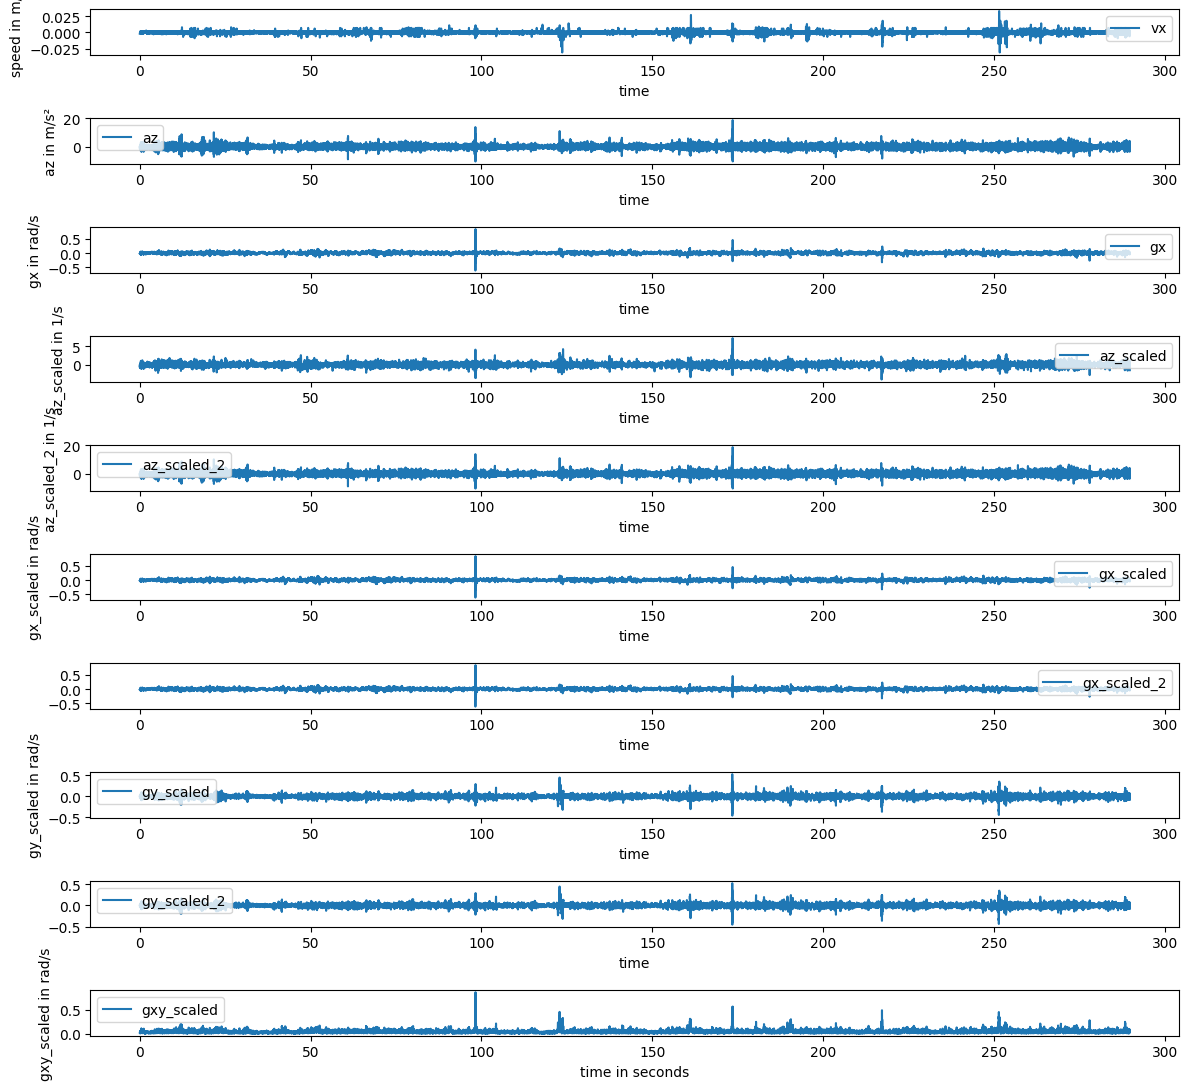

min: -0.6126105674500096 at time 98.235539424
max: 0.8360127117052837 at time 98.276120416
min: -0.1466076571675237 at time 123.800607584
max: 0.158824961931484 at time 122.919727872
min: -0.1658062789394613 at time 160.336290784
max: 0.1692969374434499 at time 161.056855328
min: -0.28623399732707 at time 173.529209952
max: 0.45553093477052 at time 173.548936672
min: -0.3246312408709453 at time 217.251557984
max: 0.2268928027592628 at time 217.331979808
min: -0.2181661564992912 at time 98.276120416
max: 0.2932153143350474 at time 98.295768736
min: -0.317649923862968 at time 123.780608032
max: 0.4485496177625427 at time 122.879735584
min: -0.301941960595019 at time 161.216923072
max: 0.2600540585471551 at time 161.056855328
min: -0.45553093477052 at time 173.44889232
max: 0.5270894341022875 at time 173.428920992
min: -0.3647738136668149 at time 217.251557984
max: 0.2460914245312004 at time 217.27175744
98.255751456
98.235539424
123.540613952
122.899681888
161.237037696
160.496712896
173

In [ ]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

desktop_path = r"C:\Users\stratklar\Documents\Markus\ASA\Indien\Testdaten_Rikscha\pothole_compact_4"

imu_dir = os.path.join(desktop_path,"extracted_imu", "imu_data_v3.csv")
odom_dir = os.path.join(desktop_path,"extracted_odom", "odom_data_v3.csv")

imu_data = pd.read_csv(imu_dir)
odom_data = pd.read_csv(odom_dir)

imu = imu_data[["Timestamp", "index", "az", "gx", "gy"]]
odom = odom_data[["Timestamp", "vx"]]

df = pd.merge_asof(
    odom.sort_values("Timestamp"),
    imu.sort_values("Timestamp"),
    on="Timestamp",
    direction="nearest",
    tolerance=20000000
)

df["time"] = (df["Timestamp"] - df["Timestamp"].min()) / 1e9
df["gxy"] = np.sqrt(df["gx"]**2 + df["gy"]**2)
df["az"] = df["az"] - df["az"].mean()

def get_event_list():
    if desktop_path.endswith("2"):
        return [29, 49, 84]
    elif desktop_path.endswith("3"):
        return [35, 41, 97, 155, 218]
    elif desktop_path.endswith("4"):
        return [99, 124, 161, 174, 218]
    else:
        return []
    
#setting number of considered values and standard deviation for smoothing such that ratio of local and global deviation is maximal.
def find_optimal_hyperparameters(event_timestamps, column = "lin_acc"):
    optimal_window = 1
    optimal_std = 1
    range_sum = 0

    for event in event_timestamps:
        if(column in ["lin_acc", "lin_acc_2"]):
            range_sum += (df[(df["time"] > event - 2) & (df["time"] < event + 2)]["az"].max() - df[(df["time"] > event - 2) & (df["time"] < event + 2)]["az"].min()) / df["az"].std()
        elif(column in ["ang_vel_x", "ang_vel_x_2"]):
            range_sum += (df[(df["time"] > event - 2) & (df["time"] < event + 2)]["gx"].max() - df[(df["time"] > event - 2) & (df["time"] < event + 2)]["gx"].min()) / df["gx"].std()
        elif(column in ["ang_vel_y", "ang_vel_y_2"]):
            range_sum += (df[(df["time"] > event - 2) & (df["time"] < event + 2)]["gy"].max() - df[(df["time"] > event - 2) & (df["time"] < event + 2)]["gy"].min()) / df["gy"].std()
        elif(column == "ang_vel_abs"):
            mu = df["gxy"].mean()
            range_sum += (df[(df["time"] > event - 2) & (df["time"] < event + 2)]["gxy"].max() - mu) / df["gxy"].std()
        else:
            return optimal_window, optimal_std

    optimal_score = range_sum
    
    for i in [1,2,3,4,5,6,7,8,9,10,20,50]:
         for std in [1,2,3,5,7,10]:
            range_sum = 0

            value_range = np.arange(-i,i+1)
            weights = np.exp(-value_range**2 / (2 * std**2))
            weights /= weights.sum()

            if column == "lin_acc":                    
                df["scaled_test"] = df["az"].rolling(2*i+1, center=True).apply(lambda x: np.dot(x, weights), raw=True)
            elif column == "lin_acc_2":
                df["az_test_positive"] = df["az"].rolling(2*i+1, center=True).apply(lambda x: np.dot(np.maximum(x, 0), weights), raw=True)
                df["az_test_negative"] = df["az"].rolling(2*i+1, center=True).apply(lambda x: np.dot(np.maximum(-x, 0), weights), raw=True)
                df["scaled_test"] = np.maximum(df["az_test_positive"], df["az_test_negative"]) * np.sign(df["az_test_positive"] - df["az_test_negative"])
            elif column == "ang_vel_x":
                df["scaled_test"] = df["gx"].rolling(2*i+1, center=True).apply(lambda x: np.dot(x, weights), raw=True)
            elif column == "ang_vel_x_2":
                df["gx_test_positive"] = df["gx"].rolling(2*i+1, center=True).apply(lambda x: np.dot(np.maximum(x, 0), weights), raw=True)
                df["gx_test_negative"] = df["gx"].rolling(2*i+1, center=True).apply(lambda x: np.dot(np.maximum(-x, 0), weights), raw=True)
                df["scaled_test"] = np.maximum(df["gx_test_positive"], df["gx_test_negative"]) * np.sign(df["gx_test_positive"] - df["gx_test_negative"])
            elif column == "ang_vel_y":
                df["scaled_test"] = df["gy"].rolling(2*i+1, center=True).apply(lambda x: np.dot(x, weights), raw=True)
            elif column == "ang_vel_y_2":
                df["gy_test_positive"] = df["gy"].rolling(2*i+1, center=True).apply(lambda x: np.dot(np.maximum(x, 0), weights), raw=True)
                df["gy_test_negative"] = df["gy"].rolling(2*i+1, center=True).apply(lambda x: np.dot(np.maximum(-x, 0), weights), raw=True)
                df["scaled_test"] = np.maximum(df["gy_test_positive"], df["gy_test_negative"]) * np.sign(df["gy_test_positive"] - df["gy_test_negative"])
            elif column == "ang_vel_abs":
                df["scaled_test"] = df["gxy"].rolling(2*i+1, center=True).apply(lambda x: np.dot(x, weights), raw=True)
                mu = df["gxy"].mean()
                for event in event_timestamps:
                    range_sum += df[(df["time"] > event - 2) & (df["time"] < event + 2)]["scaled_test"].max() - mu               
                score = range_sum / df["scaled_test"].std()
            else:
                optimal_window = 1
                optimal_std = 1
                return optimal_window, optimal_std

            if column != "ang_vel_abs":
                for event in event_timestamps:
                    range_sum += (df[(df["time"] > event - 2) & (df["time"] < event + 2)]["scaled_test"].max() - df[(df["time"] > event - 2) & (df["time"] < event + 2)]["scaled_test"].min())

                score = range_sum / df["scaled_test"].std()

            if column in ["ang_vel_x_2", "ang_vel_y_2"]:
                print(f"i: {i}, std: {std}, score: {score}")
            if score > optimal_score:
                optimal_window = 2 * i + 1
                optimal_std = std
                optimal_score = score

    print(f"optimal window for {column}: {optimal_window}")
    print(f"optimal std for {column}: {optimal_std}")
    return optimal_window, optimal_std

#az_2 uses only values of the same sign to calculate the weighted mean for smoothing
window_az, std_az = find_optimal_hyperparameters(get_event_list(), "lin_acc")
window_az_2, std_az_2 = find_optimal_hyperparameters(get_event_list(), "lin_acc_2")
window_gx, std_gx = find_optimal_hyperparameters(get_event_list(), "ang_vel_x")
window_gx_2, std_gx_2 = find_optimal_hyperparameters(get_event_list(), "ang_vel_x_2")
window_gy, std_gy = find_optimal_hyperparameters(get_event_list(), "ang_vel_y")
window_gy_2, std_gy_2 = find_optimal_hyperparameters(get_event_list(), "ang_vel_y_2")
window_gxy, std_gxy = find_optimal_hyperparameters(get_event_list(), "ang_vel_abs")

x_az = np.arange(- (window_az - 1) / 2, (window_az + 1) / 2)
x_az_2 = np.arange(- (window_az_2 - 1) / 2, (window_az_2 + 1) / 2)
x_gx = np.arange(- (window_gx - 1) / 2, (window_gx + 1) / 2)
x_gx_2 = np.arange(- (window_gx_2 - 1) / 2, (window_gx_2 + 1) / 2)
x_gy = np.arange(- (window_gy - 1) / 2, (window_gy + 1) / 2)
x_gy_2 = np.arange(- (window_gy_2 - 1) / 2, (window_gy_2 + 1) / 2)
x_gxy = np.arange(- (window_gxy - 1) / 2, (window_gxy + 1) / 2)
weights_az = np.exp(-x_az**2 / (2 * std_az**2))
weights_az /= weights_az.sum()
weights_az_2 = np.exp(-x_az_2**2 / (2 * std_az_2**2))
weights_az_2 /= weights_az_2.sum()
weights_gx = np.exp(-x_gx**2 / (2 * std_gx**2))
weights_gx /= weights_gx.sum()
weights_gx_2 = np.exp(-x_gx_2**2 / (2 * std_gx_2**2))
weights_gx_2 /= weights_gx_2.sum()
weights_gy = np.exp(-x_gy**2 / (2 * std_gy**2))
weights_gy /= weights_gy.sum()
weights_gy_2 = np.exp(-x_gy_2**2 / (2 * std_gy_2**2))
weights_gy_2 /= weights_gy_2.sum()
weights_gxy = np.exp(-x_gxy**2 / (2 * std_gxy**2))
weights_gxy /= weights_gxy.sum()

df["az_scaled"] = df["az"].rolling(window_az, center=True).apply(lambda x: np.dot(x, weights_az), raw=True)
df["az_scaled_pos"] = df["az"].rolling(window_az_2, center=True).apply(lambda x: np.dot(np.maximum(x, 0), weights_az_2), raw=True)
df["az_scaled_neg"] = df["az"].rolling(window_az_2, center=True).apply(lambda x: np.dot(np.maximum(-x, 0), weights_az_2), raw=True)
df["az_scaled_2"] = np.maximum(df["az_scaled_pos"], df["az_scaled_neg"]) * np.sign(df["az_scaled_pos"] - df["az_scaled_neg"])
df["az_scaled_22"] = df["az_scaled"] - (np.sign(df["az_scaled"])**2 + np.sign(df["az_scaled"])) * 0.5 * df["az"].rolling(window_az, center=True).apply(lambda x: np.dot(x * (np.sign(x)**2 - np.sign(x)) * 0.5, weights_az), raw=True) - (np.sign(df["az_scaled"])**2 - np.sign(df["az_scaled"])) * 0.5 * df["az"].rolling(window_az, center=True).apply(lambda x: np.dot(x * (np.sign(x)**2 + np.sign(x)) * 0.5, weights_az), raw=True) 
df["gx_scaled"] = df["gx"].rolling(window_gx, center=True).apply(lambda x: np.dot(x, weights_gx), raw=True)
df["gx_scaled_2"] = df["gx"].rolling(window_gx_2, center=True).apply(lambda x: np.dot(x, weights_gx_2), raw=True)
df["gy_scaled"] = df["gy"].rolling(window_gy, center=True).apply(lambda x: np.dot(x, weights_gy), raw=True)
df["gy_scaled_2"] = df["gy"].rolling(window_gy_2, center=True).apply(lambda x: np.dot(x, weights_gy_2), raw=True)
df["gxy_scaled"] = df["gxy"].rolling(window_gxy, center=True).apply(lambda x: np.dot(x, weights_gxy), raw=True)

fig, axes = plt.subplots(10, 1, figsize=(12, 11))

df.plot("time", "vx", ax = axes[0])
df.plot(x = "time", y = "az", ax = axes[1])
df.plot("time", "gx", ax = axes[2])
df.plot("time", "az_scaled", ax = axes[3])
df.plot("time", "az_scaled_2", ax = axes[4])
df.plot("time", "gx_scaled", ax = axes[5])
df.plot("time", "gx_scaled_2", ax = axes[6])
df.plot("time", "gy_scaled", ax = axes[7])
df.plot("time", "gy_scaled_2", ax = axes[8])
df.plot("time", "gxy_scaled", ax = axes[9])
#df.plot("time", "orientation_roll") #orientation_roll and orientation_pitch are swapped in the dataset
#df.plot("time", "gyroscope_z", ax = axes[6])

axes[0].set_ylabel("speed in m/s")
axes[1].set_ylabel("az in m/s²")
axes[2].set_ylabel("gx in rad/s")
axes[3].set_ylabel("az_scaled in 1/s")
axes[4].set_ylabel("az_scaled_2 in 1/s")
axes[5].set_ylabel("gx_scaled in rad/s")
axes[7].set_ylabel("gy_scaled in rad/s")
axes[9].set_ylabel("gxy_scaled in rad/s")
axes[9].set_xlabel("time in seconds")

plt.tight_layout()
plt.show()

def identify_peaks_az(events):
    for event in events:
        df_event = df[(df["time"] > event - 2) & (df["time"] < event + 2)]
        peak_min = df_event.loc[df_event["az"].idxmin(), "time"]
        peak_max = df_event.loc[df_event["az"].idxmax(), "time"]
        print(f"min: {df_event['az'].min()} at time {peak_min}")
        print(f"max: {df_event['az'].max()} at time {peak_max}")

def identify_peaks_gx(events):
    for event in events:
        df_event = df[(df["time"] > event - 2) & (df["time"] < event + 2)]
        peak_min = df_event.loc[df_event["gx"].idxmin(), "time"]
        peak_max = df_event.loc[df_event["gx"].idxmax(), "time"]
        print(f"min: {df_event['gx'].min()} at time {peak_min}")
        print(f"max: {df_event['gx'].max()} at time {peak_max}")

def identify_peaks_gy(events):
    for event in events:
        df_event = df[(df["time"] > event - 2) & (df["time"] < event + 2)]
        peak_min = df_event.loc[df_event["gy"].idxmin(), "time"]
        peak_max = df_event.loc[df_event["gy"].idxmax(), "time"]
        print(f"min: {df_event['gy'].min()} at time {peak_min}")
        print(f"max: {df_event['gy'].max()} at time {peak_max}")

def identify_peaks():
    events = get_event_list()
    z = 0
    az_range_distance = 0
    az_gxy_distance = 0
    #average delay relative to az_min
    az_max_delay = 0
    gxy_max_delay = 0
    for event in events:
        z += 1
        df_event = df[(df["time"] > event - 2) & (df["time"] < event + 2)]
        az_min = df_event.loc[df_event["az"].idxmin(), "time"]
        az_max = df_event.loc[df_event["az"].idxmax(), "time"]
        gxy_max = df_event.loc[df_event["gxy"].idxmax(), "time"]

        az_range_distance += abs(az_max - az_min)
        az_gxy_distance += abs((az_max + az_min)/2 - gxy_max)
        az_max_delay += az_max - az_min
        gxy_max_delay += gxy_max - az_min
        print(f"{az_min}")
        print(f"{az_max}")

    print(f"time between min and max: {az_range_distance / z}")
    print(f"gxy_max delay from az_center: {az_gxy_distance / z}")
    print(f"average time from az_min to az_max: {az_max_delay / z}")
    print(f"gxy_max delay from az_min: {gxy_max_delay / z}")


identify_peaks_gx(get_event_list())
identify_peaks_gy(get_event_list())
identify_peaks()